# Práctica 3: Aprendizaje No Supervisado, Clustering y PCA
**Módulo Profesional:** Sistemas de Aprendizaje Automático (Código 5072)  
**Especialización:** Inteligencia Artificial y Big Data (RD 279/2021)  
**Unidad Didáctica 2:** Caracterización de sistemas de aprendizaje automático (Puntos 2.4.4 y 2.4.6 de Marcombo)  
**Criterios de Evaluación Cubiertos:** **CE 2.b** (Tipos y usos), **CE 2.c** (Técnicas) y **CE 2.e** (Asociación de algoritmos no supervisados a problemas).

---

### Objetivos de la Práctica:
1. Experimentar la ausencia de etiquetas reales ($y$) en **Aprendizaje No Supervisado** para el descubrimiento autónomo de patrones latentes.
2. Implementar el algoritmo de **$K$-Medias ($K$-Means)**, utilizando la Inercia y el **Método del Codo (*Elbow Method*)** para seleccionar el valor óptimo de $K$.
3. Construir una jerarquía de agrupamiento con **Clustering Jerárquico Aglomerativo (HCA)** y visualizar su **Dendrograma**.
4. Aplicar **Análisis de Componentes Principales (PCA)** para la reducción de dimensionalidad, evaluando el porcentaje de **Varianza Explicada Acumulada** y proyectando datos en 2D.

## Bloque 1: Configuración del Entorno e Importación de Librerías

In [ ]:
# =====================================================================
# PASO 1: CONFIGURACIÓN DEL ENTORNO E IMPORTACIÓN DE LIBRERÍAS
# Práctica 3: Aprendizaje No Supervisado (Clustering y PCA)
# (Referencia Marcombo: Unidad 2, Pág. 40-44 / Puntos 2.4.4 y 2.4.6)
# =====================================================================

# 1. LIBRERÍAS FUNDAMENTALES DE PROCESAMIENTO NUMÉRICO Y TABULAR
import numpy as np         # Operaciones matriciales y cálculo vectorial avanzado
import pandas as pd        # Estructuras de datos tabulares (DataFrames) y manipulación de tablas

# 2. LIBRERÍAS DE VISUALIZACIÓN GRÁFICA
import matplotlib.pyplot as plt  # Creación y personalización de figuras, ejes y gráficos 2D
import seaborn as sns           # Estilización avanzada y mapas de calor (heatmaps) sobre Matplotlib

# 3. DATASETS Y PREPROCESAMIENTO (Scikit-Learn)
from sklearn.datasets import load_wine          # Dataset de vinos (13 atributos continuos de laboratorio)
from sklearn.preprocessing import StandardScaler  # Estandarización Z-score (Media=0, Desviación Típica=1)

# 4. ALGORITMOS DE APRENDIZAJE NO SUPERVISADO (Scikit-Learn)
from sklearn.cluster import KMeans                 # Algoritmo de Agrupamiento basado en Centroides (K-Medias)
from sklearn.cluster import AgglomerativeClustering  # Clustering Jerárquico Aglomerativo (HCA, enfoque Ascendente)
from sklearn.decomposition import PCA              # Análisis de Componentes Principales (Reducción de Dimensión)

# 5. HERRAMIENTAS DE EVALUACIÓN Y ESTRUCTURA JERÁRQUICA (SciPy y Scikit-Learn)
from scipy.cluster.hierarchy import dendrogram, linkage  # Funciones para calcular la matriz de enlaces y graficar el Dendrograma
from sklearn.metrics import silhouette_score              # Métrica cuantitativa de cohesión y separación entre clústeres

# 6. CONFIGURACIÓN DEL ESTILO VISUAL DE LOS GRÁFICOS
# Aplicamos un estilo gráfico limpio con cuadrícula para mejorar la lectura gráfica en Colab
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Mensaje de confirmación en la consola
print('✅ Librerías para Aprendizaje No Supervisado cargadas correctamente.')

### 💡 Desglose Didáctico de las Librerías Importadas

Para explicar en clase la función específica de cada módulo dentro de este tema:

1. **`load_wine` (Dataset):**
   * Contiene análisis químicos de **13 características continuas** (alcohol, ácido málico, cenizas, flavonoides, etc.) de 178 muestras de vino.
   * **Clave No Supervisada:** En esta práctica eliminamos o ignoramos deliberadamente la variable objetivo $y$ para simular un escenario real donde el algoritmo debe agrupar los datos por similitud sin conocer las respuestas.

2. **`StandardScaler`:**
   * **Imprescindible en Agrupamiento:** Algoritmos como $K$-Medias, HCA y PCA se basan en **distancias euclídeas** o varianzas. Si el volumen de cenizas varía entre 1 y 3, y la intensidad del color entre 10 y 1000, la estandarización evita que la variable con números más grandes domine geométricamente.

3. **`KMeans` y `AgglomerativeClustering`:**
   * **$K$-Medias:** Agrupa los datos dividiendo el espacio en $K$ regiones alrededor de centroides móviles (minimiza la inercia intra-clúster).
   * **HCA (Jerárquico):** Asigna cada punto a su propio grupo y los va fusionando secuencialmente hacia arriba formando un árbol.

4. **`linkage` y `dendrogram` (SciPy):**
   * **`linkage`:** Calcula las distancias acumuladas entre grupos construyendo la matriz de enlaces (usando métodos como *Ward*).
   * **`dendrogram`:** Dibuja el gráfico en forma de árbol genealógico para visualizar a qué altura se unen los distintos grupos de datos.

5. **`PCA` (Análisis de Componentes Principales):**
   * Comprime las 13 dimensiones originales en solo **2 Componentes Principales ($PC_1$ y $PC_2$)**, reteniendo la mayor varianza posible para poder proyectar y visualizar los grupos en un plano gráfico 2D.



## Paso 2: Agrupamiento con $K$-Medias ($K$-Means) y Método del Codo

*(Referencia Marcombo: Unidad 2, Pág. 40-41 / Punto 2.4.4)*

$K$-Medias asigna observaciones a $K$ centroides minimizando la distancia cuadrática intra-clúster (inercia). Para seleccionar el número óptimo de grupos $K$, representamos la curva de inercia respecto a $K$ e identificamos el punto de inflexión o 'codo'.

In [ ]:
# =====================================================================
# PASO 2: AGRUPAMIENTO CON K-MEDIAS (K-MEANS) Y MÉTODO DEL CODO
# (Referencia Marcombo: Unidad 2/ Punto 2.4.4)
# =====================================================================

# ---------------------------------------------------------------------
# 1. CARGA DE DATOS Y CONFIGURACIÓN DEL ENTORNO NO SUPERVISADO
# ---------------------------------------------------------------------
# Cargamos el dataset analítico 'Wine' de Scikit-Learn (178 muestras con 13 atributos químicos cada una).
wine = load_wine()

# Extraemos la matriz de características continuas (alcohol, flavonoides, intensidad de color, etc.).
# NOTA DIDÁCTICA: Ignoramos la variable objetivo 'y' (clases de vino) para simular un escenario real de
# Aprendizaje No Supervisado donde no disponemos de etiquetas previas y el modelo debe agrupar autónomamente.
X_raw = wine.data

# Guardamos los nombres de las 13 variables independientes para futuras inspecciones de los datos.
feature_names = wine.feature_names


# ---------------------------------------------------------------------
# 2. ESTANDARIZACIÓN OBLIGATORIA (Z-SCORE)
# ---------------------------------------------------------------------
# K-Medias utiliza la distancia euclídea para medir la proximidad entre datos y centroides.
# Instanciamos 'StandardScaler' para transformar cada variable (media = 0, desviación típica = 1).
# Esto evita que variables con magnitudes muy grandes (ej. Prolina: 250 a 1680) aplasten geométricamente a variables de rango pequeño (ej. Ceniza: 1.3 a 3.2).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)


# ---------------------------------------------------------------------
# 3. BUCLE DE EXPERIMENTACIÓN: CÁLCULO DE LA INERCIA PARA DISTINTOS K
# ---------------------------------------------------------------------
# Inicializamos una lista vacía donde acumularemos el valor de inercia devuelto en cada iteración.
inercias = []

# Definimos un rango de prueba evaluando K (número de clústeres) desde 1 hasta 8 grupos.
k_valores = range(1, 9)

# Iteramos secuencialmente probando cada valor de K en el bucle 'for':
for k in k_valores:

    # Instanciamos el clasificador K-Medias con las siguientes propiedades:
    # - 'n_clusters=k': Número de grupos a construir en la iteración actual.
    # - 'random_state=42': Fija la semilla aleatoria para que la asignación inicial de centroides sea totalmente reproducible.
    # - 'n_init=10': Realiza 10 inicializaciones independientes con semillas distintas y selecciona la de menor inercia final.
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

    # Entrenamos el modelo ajustando las posiciones de los K centroides sobre la matriz de datos estandarizada.
    kmeans.fit(X_scaled)

    # Extraemos la inercia intra-clúster (atributo '.inertia_'), que mide la suma de distancias al cuadrado de cada punto a su centroide asignado.
    # A continuación, la guardamos en la lista acumulativa 'inercias'.
    inercias.append(kmeans.inertia_)


# ---------------------------------------------------------------------
# 4. VISUALIZACIÓN DE LA CURVA DEL MÉTODO DEL CODO (ELBOW METHOD)
# ---------------------------------------------------------------------
# Creamos la figura gráfica especificando un ancho de 8 pulgadas y alto de 4 pulgadas.
plt.figure(figsize=(8, 4))

# Dibujamos la curva trazando K en el eje X e Inercia en el eje Y ('bo-' crea puntos azules unidos por línea continua).
plt.plot(k_valores, inercias, 'bo-', linewidth=2, markersize=8)

# Configuramos títulos y etiquetas legibles para los ejes del gráfico.
plt.xlabel('Número de Clústeres (K)', fontsize=12)
plt.ylabel('Inercia Intra-clúster', fontsize=12)
plt.title('Método del Codo (Elbow Method) para K-Medias', fontsize=14, fontweight='bold')

# Trazamos una línea vertical roja discontinua en K=3 para marcar visualmente el punto de inflexión o "codo" sugerido.
plt.axvline(x=3, color='r', linestyle='--', label='K Óptimo Sugerido = 3')

# Añadimos la leyenda informativa y mostramos el gráfico en la celda de Colab.
plt.legend()
plt.show()

### 📘 Explicación Detallada por Bloques: Paso 2 ($K$-Medias y Método del Codo)

1. **Simulación No Supervisada (`X_raw = wine.data`):**
   * **Concepto clave:** A diferencia de la clasificación supervisada (donde dividimos `X` e `y` mediante `train_test_split`), aquí solo extraemos la matriz `wine.data`. El algoritmo no recibe ninguna etiqueta de respuesta correcta; su objetivo es descubrir de forma autónoma patrones o agrupaciones naturales (*clusters*) en el espacio de 13 dimensiones.

2. **Necesidad del Escalado (`StandardScaler`):**
   * **Por qué es obligatorio:** $K$-Medias asigna las observaciones al centroide más próximo calculando la **distancia euclídea** (distancia geométrica en línea recta). Sin estandarización ($Z$-score), las variables con magnitudes numéricas elevadas (ej. Prolina: $250$ a $1680$) dominarían más del 99% del cálculo geométrico, anulando el efecto de las variables de rango pequeño (ej. Ceniza: $1.3$ a $3.2$).

3. **Qué es la Inercia Intra-clúster (`kmeans.inertia_`):**
   * **Definición:** Representa la suma de los errores cuadráticos internos de cada grupo (**WCSS** — *Within-Cluster Sum of Squares*). Mide la **cohesión o densidad** interna de los clústeres.
   * **Comportamiento:**
     * Con $K=1$, la inercia es máxima porque todas las muestras se evalúan respecto a un único centroide global.
     * A medida que incrementamos $K$, la inercia **siempre disminuye** (si $K = N$ muestras, cada punto se convertiría en su propio centroide y la inercia sería exactamente $0$).

4. **Interpretación de la Graficación (*Elbow Method*):**
   * El objetivo fundamental del gráfico es identificar el **punto de inflexión ("codo")**, donde la caída drástica inicial de la inercia se frena y comienza a estabilizarse en una pendiente suave.
   * En el dataset *Wine*, la inercia cae bruscamente entre $K=1$ y $K=3$. A partir de $K=3$, añadir más grupos solo produce reducciones marginales de error, justificando cuantitativamente la elección de **$K=3$ como el número óptimo de clústeres**.


En la librería `scikit-learn`, los objetos que procesan datos (como `StandardScaler`, `MinMaxScaler` o `PCA`) heredan de una clase llamada *Transformer*. Estos transformadores tienen tres métodos fundamentales:
* `fit(X)` (Ajustar): Es la fase de aprendizaje o cálculo. El algoritmo escanea los datos X para extraer los parámetros matemáticos necesarios. En el caso del `StandardScaler`, el método `fit` calcula la media ($\mu$) y la desviación típica ($\sigma$) de cada columna. No modifica los datos, solo guarda la estadística.
* `transform(X)` (Transformar): Es la fase de aplicación. Utiliza los parámetros matemáticos previamente aprendidos mediante `fit` para modificar la matriz X. En el caso del escalador, aplica la fórmula Z-score: $z = (x - \mu) / \sigma$.
* `fit_transform(X)` (Ajustar y Transformar): Es un método de conveniencia que ejecuta ambos pasos de manera simultánea. A nivel interno de la librería (implementada habitualmente en C/Cython), `fit_transform` está altamente optimizado para ser computacionalmente más rápido y consumir menos memoria RAM que llamar a `fit()` y luego a `transform()` por separado.

Usamos `fit_transform(X_raw)` para calcular la media y desviación de los datos y, en el mismo paso y de forma optimizada, aplicar esa transformación matemática devolviendo la matriz estandarizada.

In [ ]:
# =====================================================================
# EJERCICIO PRÁCTICO 1: El Método del Codo y Asignación de Clústeres
# (Referencia Marcombo: Unidad 2 / Punto 2.4.4)[cite: 1, 7]
# =====================================================================

# 🎯 OBJETIVO DE NEGOCIO: Eres el Data Scientist de una distribuidora de vinos.
# Tienes una matriz de datos químicos estandarizada ('X_scaled') pero no sabes
# cuántos perfiles de vino distintos existen.
#
# TU TAREA: Implementar de forma autónoma el cálculo de la Inercia para buscar
# el número de grupos óptimo (K de 1 a 10), graficar el resultado, y entrenar
# el modelo definitivo.

# ---------------------------------------------------------------------
# RETO 1: BUCLE DE CÁLCULO DE INERCIAS (K de 1 a 10)
# ---------------------------------------------------------------------
inercias_alumno = []
k_rango = range(1, 11)  # Evaluamos desde 1 hasta 10 clústeres

for k in k_rango:
    # 1. Instancia el modelo KMeans.
    # PISTA: Llama a KMeans() fijando 'n_clusters=k', 'random_state=42' (para
    # que tus resultados sean idénticos a los del profesor) y 'n_init=10'.
    kmeans_k = # TU CÓDIGO AQUÍ

    # 2. Entrena el modelo sobre los datos.
    # PISTA IMPORTANTE: Usa el método .fit(). Recuerda pasarle la matriz
    # estandarizada ('X_scaled'), NUNCA los datos en bruto, o las variables
    # grandes dominarán la distancia geométrica.
    # TU CÓDIGO AQUÍ

    # 3. Extrae la inercia y guárdala.
    # PISTA: El modelo entrenado guarda la suma de los errores cuadráticos
    # internos en su atributo '.inertia_'. Añádelo a la lista 'inercias_alumno'
    # usando el método .append().
    # TU CÓDIGO AQUÍ




In [ ]:
# ---------------------------------------------------------------------
# RETO 2: REPRESENTACIÓN GRÁFICA DE LA CURVA DEL CODO
# ---------------------------------------------------------------------
plt.figure(figsize=(8, 4))

# 4. Traza la línea del gráfico para buscar visualmente el "codo".
# PISTA: Utiliza plt.plot().
# - El Eje X será tu rango de K ('k_rango').
# - El Eje Y será tu lista de errores ('inercias_alumno').
# - Usa el estilo 'go--' (línea verde discontinua con círculos) para diferenciarlo
#   del ejemplo teórico que vimos antes.
# TU CÓDIGO AQUÍ

# Personalización del gráfico (¡No necesitas tocar esto!)
plt.xlabel('Número de Clústeres (K)', fontsize=12)
plt.ylabel('Inercia Intra-clúster (WCSS)', fontsize=12)
plt.title('Ejercicio Práctico: Método del Codo (K de 1 a 10)', fontsize=14, fontweight='bold')
plt.axvline(x=3, color='r', linestyle='--', label='K Óptimo Sugerido = 3')
plt.legend()
plt.show()




In [ ]:
# ---------------------------------------------------------------------
# RETO 3: ENTRENAMIENTO DEFINITIVO Y ASIGNACIÓN DE ETIQUETAS
# ---------------------------------------------------------------------
# Una vez visto el gráfico, confirmamos que el "codo" (donde la reducción del
# error se estabiliza) está en K=3. Vamos a etiquetar a los vinos.

# 5. Instancia el modelo KMeans definitivo buscando exactamente 3 clústeres.
# PISTA: 'n_clusters=3', 'random_state=42' y 'n_init=10'.
kmeans_def = # TU CÓDIGO AQUÍ

# 6. Genera las etiquetas definitivas (0, 1, 2) para cada muestra de vino.
# PISTA: Puedes entrenar y extraer las etiquetas en un solo paso usando el
# método .fit_predict(X_scaled). Guarda el resultado en 'labels_def'.
labels_def = # TU CÓDIGO AQUÍ

# Comprobación final automática (Ejecuta para validar tu trabajo)
print(f"✅ ¡Reto superado! Se han generado {len(set(labels_def))} clústeres para {len(labels_def)} muestras de vino.")

## Paso 3: Clustering Jerárquico Aglomerativo (HCA) y Dendrograma

*(Referencia Marcombo: Unidad 2/ Punto 2.4.4 y Figura 2.24)*

El agrupamiento jerárquico aglomerativo comienza asignando cada observación a su propio clúster y fusiona sucesivamente los pares más cercanos hasta formar una estructura en árbol (Dendrograma).

In [ ]:
# =====================================================================
# PASO 3: REPRESENTACIÓN VISUAL DEL DENDROGRAMA (HCA)
# (Referencia Marcombo: Unidad 2 / Punto 2.4.4)
# =====================================================================
# OBJETIVO: A diferencia de K-Medias, el Clustering Jerárquico no requiere
# que le digamos cuántos clústeres buscar de antemano[cite: 50].
# Vamos a construir un "árbol genealógico" (Dendrograma) que nos mostrará
# cómo se van fusionando los vinos según su similitud química, de abajo hacia arriba.

# IMPORTACIÓN CLAVE: Función para calcular distancias entre grupos
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------
# 1. CÁLCULO DE LA MATRIZ DE ENLACES (LINKAGE MATRIX)
# ---------------------------------------------------------------------
# Calculamos las distancias acumuladas entre grupos.
# Usamos el método 'ward', que minimiza el incremento de la varianza
# intra-clúster en cada fusión (el mismo criterio geométrico que K-Medias).
# NOTA: 'X_scaled' debe estar ya cargado de los pasos anteriores.
linked = linkage(X_scaled, method='ward')

# ---------------------------------------------------------------------
# 2. RENDERIZADO GRÁFICO DEL DENDROGRAMA
# ---------------------------------------------------------------------
# Definimos un lienzo amplio para visualizar bien las ramas
plt.figure(figsize=(12, 5))

# Dibujamos el dendrograma.
# Para evitar un colapso visual con 178 hojas, usamos 'truncate_mode'
# para mostrar únicamente los últimos 30 nodos (las fusiones más importantes).
dendrogram(
    linked,
    truncate_mode='lastp',  # Muestra solo las últimas 'p' fusiones
    p=30,                   # Número de nodos a mostrar en la base
    leaf_rotation=90,       # Rota las etiquetas 90 grados para legibilidad
    leaf_font_size=10,
    show_contracted=True    # Muestra marcas donde se han contraído ramas ocultas
)

# ---------------------------------------------------------------------
# 3. PERSONALIZACIÓN Y TOMA DE DECISIONES (CORTE DEL ÁRBOL)
# ---------------------------------------------------------------------
plt.title('Dendrograma de Agrupamiento Jerárquico (Dataset Wine)', fontsize=14, fontweight='bold')
plt.xlabel('Número de muestras contenidas en el nodo contraído', fontsize=12)
plt.ylabel('Distancia Euclídea de Fusión (Varianza)', fontsize=12)

# EL MOMENTO DE LA DECISIÓN:
# Buscamos el "salto" vertical más largo sin líneas horizontales que lo crucen.
# Al trazar una línea horizontal en Y=10, cortamos exactamente 3 líneas verticales.
# Esto significa que la estructura natural de los datos nos sugiere crear 3 clústeres.
plt.axhline(y=15, color='r', linestyle='--', label='Corte óptimo sugerido: K=3  (y=15)')

plt.legend()
plt.show()

In [ ]:
import pandas as pd

print("🍷 Características químicas del vino 121:")
# Combinamos el array de NumPy con los nombres de las características
perfil_121 = pd.Series(wine.data[121], index=wine.feature_names)
print(perfil_121)

print(f"\n🏷️ Clase real del vino 121: {wine.target_names[wine.target[121]]} (Etiqueta: {wine.target[121]})")

In [ ]:
# =====================================================================
# EJERCICIO PRÁCTICO 2: Extracción de Clústeres (HCA) y Comparativa
# (Referencia Marcombo: Unidad 2 / Punto 2.4.4)
# =====================================================================
# 🎯 OBJETIVO DE NEGOCIO: En el paso anterior confirmamos visualmente mediante
# el Dendrograma que el conjunto de datos sugiere la existencia de 3 grupos.
#
# TU TAREA: Entrenar el algoritmo matemático de Clustering Jerárquico Aglomerativo
# para extraer las etiquetas reales (0, 1, 2) de cada vino y construir una matriz
# cruzada para auditar si HCA segmenta a los clientes exactamente igual que K-Medias.
# ---------------------------------------------------------------------

# ---------------------------------------------------------------------
# RETO 1: ENTRENAMIENTO DE AGGLOMERATIVE CLUSTERING
# ---------------------------------------------------------------------
# 1. Instancia el modelo jerárquico.
# PISTA: Utiliza 'AgglomerativeClustering', configura 'n_clusters=3' y
# el método de enlace 'linkage="ward"' para minimizar la varianza intra-clúster.
modelo_hca = # TU CÓDIGO AQUÍ

# 2. Entrena el modelo y extrae las etiquetas asignadas a cada vino.
# PISTA: Al igual que hicimos con K-Medias, el agrupamiento se puede ajustar
# y predecir en un solo paso con el método .fit_predict(X_scaled).
labels_hca = # TU CÓDIGO AQUÍ

# ---------------------------------------------------------------------
# RETO 2: DISTRIBUCIÓN Y TABLA DE CONTINGENCIA (CROSSTAB)
# ---------------------------------------------------------------------
# 3. Analiza cuántos vinos han caído en cada clúster de HCA.
print("📊 Distribución de muestras (HCA):")
# PISTA: Convierte 'labels_hca' en una pd.Series y encadena .value_counts().sort_index()
conteo_hca = # TU CÓDIGO AQUÍ
print(conteo_hca)
print("\n" + "-"*50 + "\n")

# 4. Construye una tabla cruzada para auditar las coincidencias.
# PISTA: Utiliza pd.crosstab() pasándole primero las etiquetas del reto
# anterior de K-Medias ('labels_def') y en segundo lugar las nuevas ('labels_hca').
print("🔀 Tabla Cruzada (K-Medias vs HCA):")
tabla_cruzada = # TU CÓDIGO AQUÍ
print(tabla_cruzada)

# ---------------------------------------------------------------------
# RETO 3: REFLEXIÓN TÉCNICA PARA MLOps (Machine Learning Operations)
# ---------------------------------------------------------------------
# TU TAREA: Escribe un breve comentario (con #) respondiendo a esta pregunta:
#
# K-Medias agrupa calculando la distancia a solo 3 centroides en memoria[cite: 51].
# HCA agrupa calculando una matriz de distancias cruzada entre todos los puntos[cite: 50].
# Si tuviéramos que desplegar un modelo en un servidor para clasificar 50.000
# nuevas lecturas de sensores químicos por minuto...
# ¿Qué algoritmo colapsaría la memoria RAM del servidor y por qué?
#
# RESPUESTA DEL ALUMNO:
#

## Paso 4: Reducción de Dimensionalidad con PCA

*(Referencia Marcombo: Unidad 2/ Punto 2.4.6 y Figuras 2.27 y 4.37)*

El **Análisis de Componentes Principales (PCA)** proyecta el dataset de 13 características originales a un espacio reducido de 2 componentes principales ($PC_1, PC_2$) conservando la máxima varianza explicada posible.

📊 Varianza explicada por PC1 (Dirección de máxima dispersión): 36.20%
📊 Varianza explicada por PC2 (Eje ortogonal secundario): 19.21%
💡 Varianza Acumulada Retenida en 2D: 55.41%



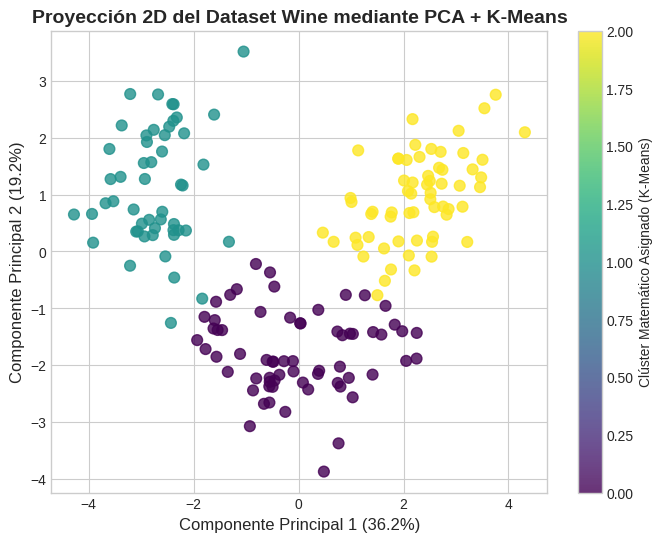

In [11]:
# =====================================================================
# EJEMPLO GUIADO: Reducción de Dimensionalidad (PCA) + K-Medias
# =====================================================================
# OBJETIVO TÉCNICO: Resolver el problema de la visualización humana en
# hiperespacios. Se utiliza PCA para comprimir las 13 dimensiones químicas
# del dataset Wine a 2 Componentes Principales, con el objetivo de que la
# pérdida de información ocasionada sea mínima.
# Posteriormente, se proyectan los clústeres reales (calculados en 13D)
# sobre este plano 2D para su interpretación visual.
# ---------------------------------------------------------------------

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

# 1. REDUCCIÓN DE DIMENSIONALIDAD (PCA)
# ---------------------------------------------------------------------
# Instanciamos el modelo PCA indicando que deseamos exactamente 2 componentes.
pca = PCA(n_components=2, random_state=42)

# El método fit_transform aprende la transformación óptima y la aplica sobre 'X_scaled'.
# ATENCIÓN: Las nuevas componentes principales (PC1 y PC2) no tienen un significado
# sobre el conjunto de datos original.
# Estas componentes están construidas en base a combinaciones lineales de las
# variables iniciales.
X_pca = pca.fit_transform(X_scaled)

# Cálculo de la varianza explicada (cuánta información geométrica se ha salvado).
varianza_exp = pca.explained_variance_ratio_
varianza_acum = np.sum(varianza_exp)

print(f'📊 Varianza explicada por PC1 (Dirección de máxima dispersión): {varianza_exp[0]*100:.2f}%')
print(f'📊 Varianza explicada por PC2 (Eje ortogonal secundario): {varianza_exp[1]*100:.2f}%')
print(f'💡 Varianza Acumulada Retenida en 2D: {varianza_acum*100:.2f}%\n')


# 2. AGRUPAMIENTO MATEMÁTICO EN ALTA DIMENSIÓN (K-MEDIAS)
# ---------------------------------------------------------------------
# Instanciamos K-Medias buscando 3 grupos, basándonos en el "Método del Codo" previo.
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)

# CLAVE METODOLÓGICA: El agrupamiento (.fit_predict) se ejecuta ESTRICTAMENTE
# sobre 'X_scaled' (13 dimensiones originales).
# K-Medias realiza el agrupamiento resolviendo un problema de optimización en el que
# se minimiza la distancia cuadrática de cada dato al centroide de su grupo.
# Si agrupáramos sobre 'X_pca', obligaríamos al algoritmo a calcular distancias con
# una pérdida de casi el 45% de la varianza original.
labels_kmeans = kmeans_final.fit_predict(X_scaled)


# 3. PROYECCIÓN VISUAL 2D
# ---------------------------------------------------------------------
plt.figure(figsize=(8, 6))

# Trazamos el gráfico de dispersión (scatter).
# X_pca[:, 0] corresponde al eje X (PC1).
# X_pca[:, 1] corresponde al eje Y (PC2).
# 'c=labels_kmeans' colorea cada punto según la etiqueta del clúster matemático.
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_kmeans, cmap='viridis', s=60, alpha=0.8)

# Personalización de la gráfica para entornos profesionales.
plt.xlabel(f'Componente Principal 1 ({varianza_exp[0]*100:.1f}%)', fontsize=12)
plt.ylabel(f'Componente Principal 2 ({varianza_exp[1]*100:.1f}%)', fontsize=12)
plt.title('Proyección 2D del Dataset Wine mediante PCA + K-Means', fontsize=14, fontweight='bold')
plt.colorbar(scatter, label='Clúster Matemático Asignado (K-Means)')

# Renderizado final del gráfico en el cuaderno
plt.show()

###Recordad:

* El desafío de la alta dimensionalidad: K-Medias ha calculado la distancia euclídea en un espacio de 13 dimensiones (los 13 atributos químicos del vino). Como es imposible graficar esto, PCA actúa como un proyector de sombras: comprime los datos a 2D garantizando que la pérdida de información sea mínima al maximizar la varianza retenida

* Separación de responsabilidades (Clustering vs. Visualización): K-Medias no agrupó los puntos basándose en el gráfico 2D. El algoritmo agrupó los vinos minimizando la distancia cuadrática a los centroides en las 13 dimensiones originales. El gráfico PCA es solo una herramienta de validación visual posterior para ver si esos grupos matemáticos tienen sentido geométrico para el ojo humano.

* Transición al Reto Práctico: Aquí vemos cómo K-Medias agrupa minimizando la distancia a un centroide central. En el siguiente reto, programaréis un Clustering Jerárquico Aglomerativo. En lugar de buscar centros, este algoritmo partirá de cada observación aislada y fusionará los puntos más parecidos construyendo una matriz de distancias paso a paso. Vuestra misión será comprobar si ambas lógicas matemáticas llegan a la misma conclusión operativa.

In [ ]:
# =====================================================================
# EJERCICIO PRÁCTICO: Aprendizaje Supervisado y Matriz de Confusión
# (Referencia Marcombo: Unidad 3 y Unidad 6)[cite: 7, 8]
# =====================================================================
# 🎯 OBJETIVO DE NEGOCIO: Ahora SÍ tenemos las respuestas correctas (etiquetas).
# Eres el Ingeniero de Machine Learning de la bodega y debes entrenar un
# algoritmo de "Bosque Aleatorio" (Random Forest) para clasificar automáticamente
# los vinos. Además, debes auditar dónde se equivoca el modelo usando
# una Matriz de Confusión.
# ---------------------------------------------------------------------

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Cargamos los datos (X: características químicas, y: clase real de vino)
wine = load_wine()
X = wine.data
y = wine.target

# ---------------------------------------------------------------------
# RETO 1: DIVISIÓN DE LOS DATOS (TRAIN / TEST)
# ---------------------------------------------------------------------
# REGLA DE ORO: Un modelo nunca debe evaluarse con los datos que usó para aprender.
# 1. Divide el dataset guardando un 20% de los datos para el Testeo (test_size=0.2).
# PISTA: Usa la función train_test_split y fija random_state=42 para reproducibilidad.
X_train, X_test, y_train, y_test = # TU CÓDIGO AQUÍ

print(f"📊 Datos para entrenar: {X_train.shape[0]} vinos.")
print(f"📊 Datos para examinar al modelo: {X_test.shape[0]} vinos.\n")


# ---------------------------------------------------------------------
# RETO 2: ENTRENAMIENTO DEL MODELO SUPERVISADO
# ---------------------------------------------------------------------
# El algoritmo Random Forest crea múltiples árboles de decisión y
# selecciona la clase más votada entre todos ellos[cite: 35, 36].

# 2. Instancia el clasificador Random Forest (fija random_state=42)
modelo_rf = # TU CÓDIGO AQUÍ

# 3. Entrena el modelo pasándole EXCLUSIVAMENTE los datos de entrenamiento (X e y).
# TU CÓDIGO AQUÍ


# ---------------------------------------------------------------------
# RETO 3: INFERENCIA Y EVALUACIÓN (MATRIZ DE CONFUSIÓN)
# ---------------------------------------------------------------------
# 4. Pídele al modelo que prediga las clases de los vinos que reservamos
# para el examen (X_test).
# PISTA: Utiliza el método .predict()
predicciones = # TU CÓDIGO AQUÍ

# 5. Calcula la precisión global (Accuracy) comparando las predicciones
# con las respuestas reales (y_test).
precision = # TU CÓDIGO AQUÍ
print(f"🎯 Precisión Global del Modelo: {precision * 100:.2f}%\n")

# 6. Genera la Matriz de Confusión para ver exactamente dónde ha fallado[cite: 8].
# PISTA: La función confusion_matrix necesita (respuestas_reales, predicciones).
matriz = # TU CÓDIGO AQUÍ

# Renderizado visual de la Matriz de Confusión (No necesitas modificar esto)
plt.figure(figsize=(6, 4))
sns.heatmap(matriz, annot=True, cmap="Blues", fmt="d",
            xticklabels=wine.target_names, yticklabels=wine.target_names)
plt.title("Matriz de Confusión: Clasificación de Vinos", fontweight='bold')
plt.xlabel("Predicción del Modelo")
plt.ylabel("Clase Real")
plt.show()

In [ ]:
# =====================================================================
# EJERCICIO PRÁCTICO: Clustering Jerárquico (HCA) vs K-Medias
# (Referencia Marcombo: Unidad 2 / Punto 2.4.4)[cite: 7]
# =====================================================================
# OBJETIVO: Entrenar el modelo de Clustering Jerárquico Aglomerativo (HCA)
# utilizando K=3 clústeres y el método de enlace 'ward'.
# Posteriormente, contrastaremos empíricamente si HCA segmenta los vinos
# de la misma forma que lo hizo K-Medias en el reto anterior.
# ---------------------------------------------------------------------

# NOTA DIDÁCTICA: Asegúrate de haber ejecutado las celdas anteriores.
# Necesitamos en memoria la matriz estandarizada de vinos 'X_scaled' y las
# etiquetas generadas por K-Medias ('labels_def').

# ---------------------------------------------------------------------
# RETO 1: INSTANCIACIÓN Y ENTRENAMIENTO DE AGGLOMERATIVE CLUSTERING
# ---------------------------------------------------------------------
# 1. Instancia el modelo jerárquico definiendo 3 clústeres.
# Utiliza el método de enlace (linkage) 'ward' para minimizar la varianza intra-clúster.
# PISTA: Utiliza la clase AgglomerativeClustering que importamos en el Paso 1.
modelo_hca = # TU CÓDIGO AQUÍ

# 2. Ajusta el modelo a los datos estandarizados (X_scaled) y extrae las etiquetas.
# PISTA: En scikit-learn, el agrupamiento se puede ajustar y predecir en un solo paso.
labels_hca = # TU CÓDIGO AQUÍ

# ---------------------------------------------------------------------
# RETO 2: ANÁLISIS DE DISTRIBUCIÓN Y TABLA DE CONTINGENCIA
# ---------------------------------------------------------------------
# 3. Muestra cuántas muestras de vino han caído en cada clúster de HCA.
print("📊 Distribución de muestras por Clúster en HCA (K=3):")
# PISTA: Transforma las etiquetas en una pd.Series y encadena .value_counts().sort_index()
conteo_hca = # TU CÓDIGO AQUÍ
print(conteo_hca)
print("\n" + "-"*50 + "\n")

# 4. Construye una tabla cruzada para comparar las etiquetas de K-Medias vs HCA.
# PISTA: Utiliza la función pd.crosstab() de Pandas pasando 'labels_def' (K-Medias) y 'labels_hca' (HCA).
print("🔀 Tabla Cruzada de Coincidencias (K-Medias vs HCA):")
tabla_cruzada = # TU CÓDIGO AQUÍ
print(tabla_cruzada)

# ---------------------------------------------------------------------
# RETO 3 (BUSINESS ROLE-PLAY): INTERPRETACIÓN DE RESULTADOS
# ---------------------------------------------------------------------
# TU TAREA: Escribe un breve comentario (con #) respondiendo a esta pregunta:
# Si fueras el Lead Data Scientist de una bodega, ¿por qué crees que ambos algoritmos
# no coinciden al 100% en la segmentación de los vinos, y cuál de los dos
# llevarías a producción en tu arquitectura de software si la bodega generara miles
# de datos sensóricos nuevos al día?
#
# RESPUESTA:
#

## Wrap-Up: Consolidación de Conceptos (Práctica 3)

1. **Agrupamiento Autónomo:** $K$-Medias y el Clustering Jerárquico permiten agrupar observaciones similares sin requerir etiquetas de supervisión previas.
2. **Selección de $K$:** El Método del Codo y el Coeficiente Silhouette son herramientas cuantitativas esenciales para justificar la elección del número de clústeres.
3. **Compresión de Datos (PCA):** PCA permite reducir la dimensionalidad maximizando la varianza explicada, facilitando la visualización y eliminando redundancias mecánicas.

#SOLUCIONES



In [ ]:
#@title SOLUCIÓN Cálculo del Método del Codo y Asignación de Clústeres
# =====================================================================

# ---------------------------------------------------------------------
# RETO 1: BUCLE DE CÁLCULO DE INERCIAS (K de 1 a 10)
# ---------------------------------------------------------------------
inercias_alumno = []
k_rango = range(1, 11)

for k in k_rango:
    # 1. Instanciación con k clústeres y semilla reproducible
    kmeans_k = KMeans(n_clusters=k, random_state=42, n_init=10)

    # 2. Ajuste sobre la matriz de características estandarizadas
    kmeans_k.fit(X_scaled)

    # 3. Almacenamiento del valor de Inercia Intra-clúster (WCSS)
    inercias_alumno.append(kmeans_k.inertia_)


# ---------------------------------------------------------------------
# RETO 2: REPRESENTACIÓN GRÁFICA DE LA CURVA DEL CODO
# ---------------------------------------------------------------------
plt.figure(figsize=(8, 4))

# 4. Graficado de K frente a la Inercia acumulada
plt.plot(k_rango, inercias_alumno, 'bo-', linewidth=2, markersize=8)

plt.xlabel('Número de Clústeres (K)', fontsize=12)
plt.ylabel('Inercia Intra-clúster (WCSS)', fontsize=12)
plt.title('Ejercicio Práctico: Método del Codo (K de 1 a 10)', fontsize=14, fontweight='bold')
plt.axvline(x=3, color='r', linestyle='--', label='K Óptimo Sugerido = 3')
plt.legend()
plt.show()


# ---------------------------------------------------------------------
# RETO 3: ENTRENAMIENTO DEFINITIVO CON K=3 Y ASIGNACIÓN DE ETIQUETAS
# ---------------------------------------------------------------------
# 5. Instanciación del modelo óptimo con K=3
kmeans_def = KMeans(n_clusters=3, random_state=42, n_init=10)

# 6. Ajuste y asignación de etiquetas definitivas
labels_def = kmeans_def.fit_predict(X_scaled)

print(f"✅ Ejercicio completado: Se han generado {len(set(labels_def))} clústeres para {len(labels_def)} muestras de vino.")

In [ ]:
#@title SOLUCIÓN: El Método del Codo y Asignación de Clústeres
# (Referencia Marcombo: Unidad 2 / Punto 2.4.4)[cite: 1, 7]
# =====================================================================

# 🎯 OBJETIVO DE NEGOCIO: Eres el Data Scientist de una distribuidora de vinos.
# Tienes una matriz de datos químicos estandarizada ('X_scaled') pero no sabes
# cuántos perfiles de vino distintos existen.
#
# TU TAREA: Implementar de forma autónoma el cálculo de la Inercia para buscar
# el número de grupos óptimo (K de 1 a 10), graficar el resultado, y entrenar
# el modelo definitivo.

# ---------------------------------------------------------------------
# RETO 1: BUCLE DE CÁLCULO DE INERCIAS (K de 1 a 10)
# ---------------------------------------------------------------------
inercias_alumno = []
k_rango = range(1, 11)  # Evaluamos desde 1 hasta 10 clústeres

for k in k_rango:
    # 1. Instancia el modelo KMeans.
    kmeans_k = KMeans(n_clusters=k, random_state=42, n_init=10)

    # 2. Entrena el modelo sobre los datos.
    kmeans_k.fit(X_scaled)

    # 3. Extrae la inercia y guárdala.
    inercias_alumno.append(kmeans_k.inertia_)


# ---------------------------------------------------------------------
# RETO 2: REPRESENTACIÓN GRÁFICA DE LA CURVA DEL CODO
# ---------------------------------------------------------------------
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

# 4. Traza la línea del gráfico para buscar visualmente el "codo".
plt.plot(k_rango, inercias_alumno, 'go--', linewidth=2, markersize=8)

# Personalización del gráfico (¡No necesitas tocar esto!)
plt.xlabel('Número de Clústeres (K)', fontsize=12)
plt.ylabel('Inercia Intra-clúster (WCSS)', fontsize=12)
plt.title('Ejercicio Práctico: Método del Codo (K de 1 a 10)', fontsize=14, fontweight='bold')
plt.axvline(x=3, color='r', linestyle='--', label='K Óptimo Sugerido = 3')
plt.legend()
plt.show()


# ---------------------------------------------------------------------
# RETO 3: ENTRENAMIENTO DEFINITIVO Y ASIGNACIÓN DE ETIQUETAS
# ---------------------------------------------------------------------
# Una vez visto el gráfico, confirmamos que el "codo" (donde la reducción del
# error se estabiliza) está en K=3. Vamos a etiquetar a los vinos.

# 5. Instancia el modelo KMeans definitivo buscando exactamente 3 clústeres.
kmeans_def = KMeans(n_clusters=3, random_state=42, n_init=10)

# 6. Genera las etiquetas definitivas (0, 1, 2) para cada muestra de vino.
labels_def = kmeans_def.fit_predict(X_scaled)

# Comprobación final automática (Ejecuta para validar tu trabajo)
print(f"✅ ¡Reto superado! Se han generado {len(set(labels_def))} clústeres para {len(labels_def)} muestras de vino.")

In [ ]:
#@title SOLUCIÓN Extracción de Clústeres (HCA) y Comparativa
# RETO 1: ENTRENAMIENTO DE AGGLOMERATIVE CLUSTERING
# ---------------------------------------------------------------------
modelo_hca = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_hca = modelo_hca.fit_predict(X_scaled)

# ---------------------------------------------------------------------
# RETO 2: DISTRIBUCIÓN Y TABLA DE CONTINGENCIA (CROSSTAB)
# ---------------------------------------------------------------------
print("📊 Distribución de muestras (HCA):")
conteo_hca = pd.Series(labels_hca).value_counts().sort_index()
print(conteo_hca)
print("\n" + "-"*50 + "\n")

print("🔀 Tabla Cruzada (K-Medias vs HCA):")
tabla_cruzada = pd.crosstab(labels_def, labels_hca,
                            rownames=['K-Medias'],
                            colnames=['HCA'])
print(tabla_cruzada)

# ---------------------------------------------------------------------
# SOLUCIÓN RETO 3
# HCA colapsaría la RAM. Su complejidad cuadrática O(N^2) obliga a recalcular
# la matriz de distancias contra todo el histórico de datos ante cada lectura
# nueva. K-Medias es mucho más eficiente O(K*N) porque la nueva lectura
# sensórica solo debe compararse contra los 3 centroides guardados en memoria.

📊 Datos para entrenar: 142 vinos.
📊 Datos para examinar al modelo: 36 vinos.

🎯 Precisión Global del Modelo: 100.00%



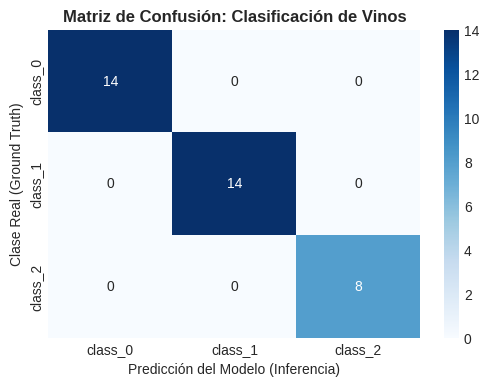

In [12]:
#@title SOLUCIÓN : Aprendizaje Supervisado y Matriz de Confusión
# =====================================================================
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

wine = load_wine()
X = wine.data
y = wine.target

# 1. DIVISIÓN DE LOS DATOS (Prevención de Fuga de Datos)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"📊 Datos para entrenar: {X_train.shape[0]} vinos.")
print(f"📊 Datos para examinar al modelo: {X_test.shape[0]} vinos.\n")

# 2. ENTRENAMIENTO DEL MODELO (Random Forest)
modelo_rf = RandomForestClassifier(random_state=42)

# El método .fit() ahora recibe DOS parámetros (X_train y y_train).
# El algoritmo aprende a relacionar la química (X) con la etiqueta real (y).
modelo_rf.fit(X_train, y_train)

# 3. INFERENCIA Y EVALUACIÓN
# Hacemos la predicción solo sobre las características del Test (X_test).
# El modelo NO ve las etiquetas y_test.
predicciones = modelo_rf.predict(X_test)

# Evaluamos comparando lo que predijo frente a la realidad.
precision = accuracy_score(y_test, predicciones)
print(f"🎯 Precisión Global del Modelo: {precision * 100:.2f}%\n")

# La Matriz de Confusión cruza las clases reales con las predichas[cite: 8].
matriz = confusion_matrix(y_test, predicciones)

# Visualización con Seaborn
plt.figure(figsize=(6, 4))
sns.heatmap(matriz, annot=True, cmap="Blues", fmt="d",
            xticklabels=wine.target_names, yticklabels=wine.target_names)
plt.title("Matriz de Confusión: Clasificación de Vinos", fontweight='bold')
plt.xlabel("Predicción del Modelo (Inferencia)")
plt.ylabel("Clase Real (Ground Truth)")
plt.show()